# Softmax Classifier 1D — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/softmax-classifier-1d.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Softmax Classifier 1D</h1>


## Learning Objectives
After completing this lab you will be able to: 
- Build a Softmax classifier by using the Sequential module in PyTorch



<h2>Table of Contents</h2>
<p>In this lab, you will use Softmax to classify three linearly separable classes, the features are in one dimension </p>
<ol>
<li><a href="#Import-the-Libraries">Import the Libraries</a> 
</li>
<li><a href="#Create-the-Data">Create the Data</a>     
</li>   
 <li><a href="#Build-a-Softmax-Classifier">Build a Softmax Classifier</a>     
</li>
<li><a href="#Train-the-Model">Train the Model</a>     
</li>
<li><a href="#Analyze-the-Results">Analyze the Results</a>     
</li>
</ol>


<hr>


## Import the Libraries 


We'll need the following libraries:


In [2]:
import torch.nn as nn
import torch
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import Dataset, DataLoader

Matplotlib is building the font cache; this may take a moment.


Use the helper function to plot labeled data points: 


In [3]:
def plot_data(data_set, model=None, n=1, color=False):
    X = data_set[:][0]
    Y = data_set[:][1]
    plt.plot(X[Y == 0, 0].numpy(), Y[Y == 0].numpy(), 'bo', label='y = 0')
    plt.plot(X[Y == 1, 0].numpy(), 0 * Y[Y == 1].numpy(), 'ro', label='y = 1')
    plt.plot(X[Y == 2, 0].numpy(), 0 * Y[Y == 2].numpy(), 'go', label='y = 2')
    plt.ylim((-0.1, 3))
    plt.legend()
    if model != None:
        w = list(model.parameters())[0][0].detach()
        b = list(model.parameters())[1][0].detach()
        y_label = ['yhat=0', 'yhat=1', 'yhat=2']
        y_color = ['b', 'r', 'g']
        Y = []
        for w, b, y_l, y_c in zip(model.state_dict()['0.weight'], model.state_dict()['0.bias'], y_label, y_color):
            Y.append((w * X + b).numpy())
            plt.plot(X.numpy(), (w * X + b).numpy(), y_c, label=y_l)
        if color == True:
            x = X.numpy()
            x = x.reshape(-1)
            top = np.ones(x.shape)
            y0 = Y[0].reshape(-1)
            y1 = Y[1].reshape(-1)
            y2 = Y[2].reshape(-1)
            plt.fill_between(x, y0, where=y1 > y1, interpolate=True, color='blue')
            plt.fill_between(x, y0, where=y1 > y2, interpolate=True, color='blue')
            plt.fill_between(x, y1, where=y1 > y0, interpolate=True, color='red')
            plt.fill_between(x, y1, where=(y1 > y2) * (y1 > y0), interpolate=True, color='red')
            plt.fill_between(x, y2, where=(y2 > y0) * (y0 > 0), interpolate=True, color='green')
            plt.fill_between(x, y2, where=y2 > y1, interpolate=True, color='green')
    plt.legend()
    plt.show()

Set the random seed:


In [4]:
torch.manual_seed(0)

<!--Empty Space for separating topics-->


## Create the Data


Create some linearly separable data with three classes: 


In [5]:
class Data(Dataset):

    def __init__(self):
        self.x = torch.arange(-2, 2, 0.1).view(-1, 1)
        self.y = torch.zeros(self.x.shape[0])
        self.y[(self.x > -1.0)[:, 0] * (self.x < 1.0)[:, 0]] = 1
        self.y[(self.x >= 1.0)[:, 0]] = 2
        self.y = self.y.type(torch.LongTensor)
        self.len = self.x.shape[0]

    def __getitem__(self, index):
        return (self.x[index], self.y[index])

    def __len__(self):
        return self.len

Create the dataset object:


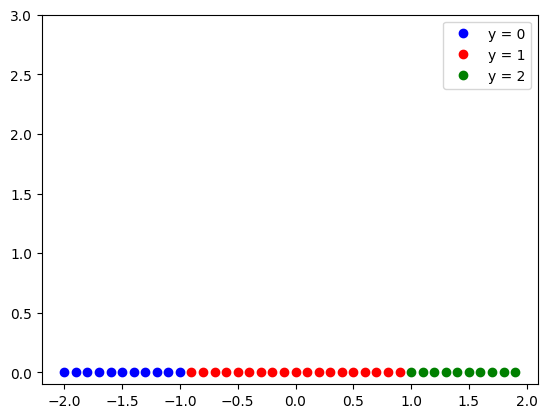

In [6]:
data_set = Data()
data_set.x
plot_data(data_set)

<!--Empty Space for separating topics-->


## Build a Softmax Classifier


Build a Softmax classifier by using the Sequential module:


In [7]:
model = nn.Sequential(nn.Linear(1, 3))
model.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0075],
                      [ 0.5364],
                      [-0.8230]])),
             ('0.bias', tensor([-0.7359, -0.3852,  0.2682]))])

<!--Empty Space for separating topics-->


<h2 id="Model">Train the Model</h2> 


Create the criterion function, the optimizer, and the dataloader:


In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
trainloader = DataLoader(dataset=data_set, batch_size=5)

Train the model and plot the line generated for each class every 50 epochs.


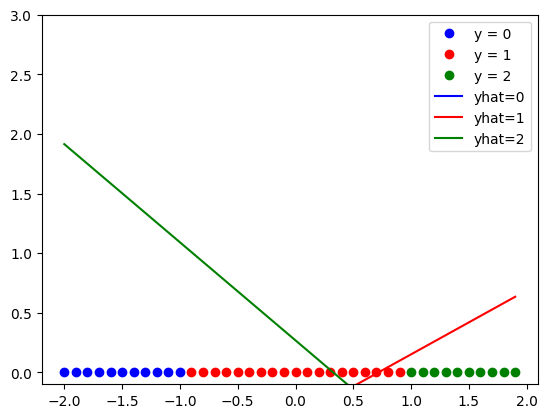

In [9]:
LOSS = []

def train_model(epochs):
    for epoch in itertools.islice(range(epochs), 2):
        if epoch % 50 == 0:
            pass
            plot_data(data_set, model)
        for x, y in trainloader:
            optimizer.zero_grad()
            yhat = model(x)
            loss = criterion(yhat, y)
            LOSS.append(loss)
            loss.backward()
            optimizer.step()
train_model(2)

<!--Empty Space for separating topics-->


## Analyze the Results


Find the predicted class on the test data: 


In [10]:
z = model(data_set.x)
_, yhat = z.max(1)
print('The prediction:', yhat)

The prediction: tensor([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


Calculate the accuracy on the test data:


In [11]:
correct = (data_set.y == yhat).sum().item()
accuracy = correct / len(data_set)
print('The accuracy: ', accuracy)

The accuracy:  0.125


You can also use the Softmax function to convert the output to a probability. First, create a Softmax object:


In [12]:
Softmax_fn = nn.Softmax(dim=-1)

The result is a tensor <code> Probability </code>, where each row corresponds to a different sample, and each column corresponds to that sample  belonging to a particular class


In [13]:
Probability = Softmax_fn(z)

We can obtain the probability of the first sample belonging to the first, second, and third class respectively as follows:


In [14]:
for i in range(3):
    print('probability of class {} isg given by  {}'.format(i, Probability[0, i]))

probability of class 0 isg given by  0.09427571296691895
probability of class 1 isg given by  0.04258160665631294
probability of class 2 isg given by  0.863142728805542


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |
-->


<hr>





## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
